# CSE 422 Project

**Group Number: 12**

Group Member Name: Sahir Jawad Chowdhury

ID: 23301212

Group Member Name: Ihfaz Rashid Sadat

ID: 23301499

Course Code: CSE422

Section: 10


# Library & Data set Imported


In [ ]:
# Core libraries
import numpy as np
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
main_df = pd.read_csv('software_quality_dataset.csv')

df= main_df.copy()
d_df=main_df.copy()
df.head(3)

,Lines_of_Code,Cyclomatic_Complexity,Num_Functions,Code_Churn,Comment_Density,Num_Bugs,Has_Unit_Tests,Code_Owner_Experience,Quality_Label
0,356.0,31,144,69.567047,0.467561,2,Yes,4,Medium
1,227.0,15,104,131.844422,0.795643,2,No,5,High
2,9674.0,47,141,118.729027,0.316839,5,No,1,High


In [ ]:
display(df)

In [ ]:
print(f"There are {d_df.shape[1]-1} features.")
print(f"There are {d_df.size} data points")
print(set(df.dtypes))

There are 8 features.
There are 14400 data points
{dtype('float64'), dtype('O'), dtype('int64')}


# Dataset Description



In [ ]:
print(d_df.isna().sum())
non_numeric_cols = d_df.select_dtypes(exclude=["number"]).columns.tolist()
print(non_numeric_cols)


Lines_of_Code            80
Cyclomatic_Complexity     0
Num_Functions             0
Code_Churn               80
Comment_Density          80
Num_Bugs                  0
Has_Unit_Tests            0
Code_Owner_Experience     0
Quality_Label             0
dtype: int64
['Has_Unit_Tests', 'Quality_Label']


In [ ]:
print(non_numeric_cols)

['Has_Unit_Tests', 'Quality_Label']


In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

for cat_col in non_numeric_cols:
    d_df[cat_col] = le.fit_transform(df[cat_col])

6. Below is the correlation of all the features after encoding.

In [ ]:
corr_df=d_df.corr()
#sns.heatmap(corr_df, cmap = 'YlGnBu')

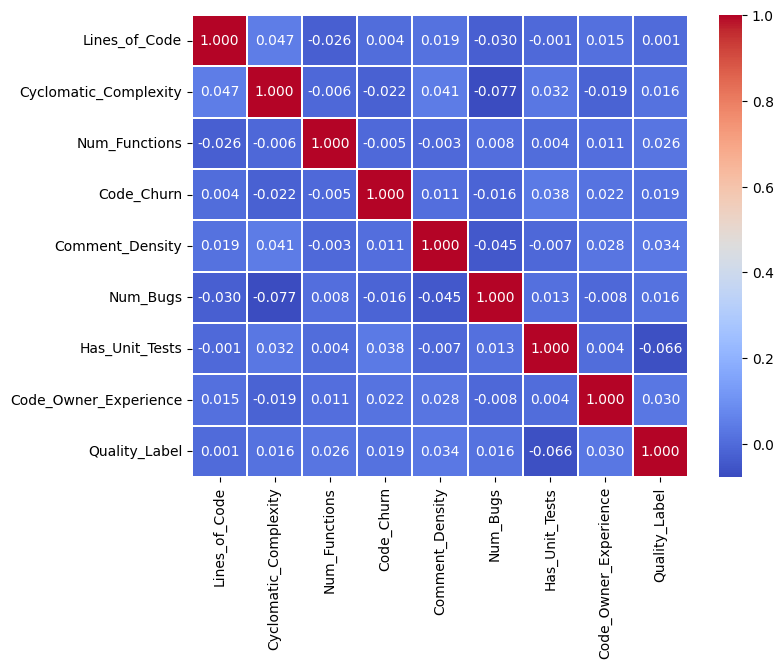

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_df, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.3)
plt.show()

In [ ]:
d_df['Quality_Label'].value_counts()

,count
Quality_Label,
0,566
1,533
2,501


In [ ]:
for i, cls in enumerate(le.classes_):
    print(i, "→", cls)

0 → High
1 → Low
2 → Medium


# Below is a visual representation using Bar Chart

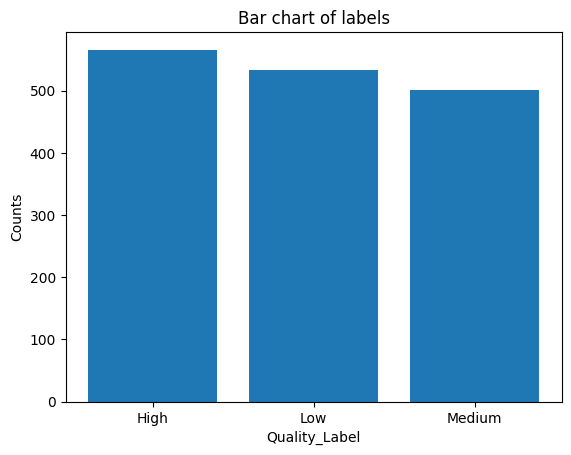

In [ ]:
labels= ["High","Low","Medium"]
values= [566,533,501]
plt.bar(labels,values)
plt.xlabel("Quality_Label")
plt.ylabel("Counts")
plt.title("Bar chart of labels")
plt.show()

# Exploratory Data Analysis

In [ ]:
eda_df=main_df.copy()

In [ ]:
eda_df

,Lines_of_Code,Cyclomatic_Complexity,Num_Functions,Code_Churn,Comment_Density,Num_Bugs,Has_Unit_Tests,Code_Owner_Experience,Quality_Label
0,356.0,31,144,69.567047,0.467561,2,Yes,4,Medium
1,227.0,15,104,131.844422,0.795643,2,No,5,High
2,9674.0,47,141,118.729027,0.316839,5,No,1,High
3,6967.0,42,107,194.397155,0.971883,5,Yes,3,Low
4,7954.0,35,114,69.202293,0.559417,1,No,8,Medium
...,...,...,...,...,...,...,...,...,...
1595,8883.0,40,31,54.863010,0.928920,3,Yes,8,Low
1596,2175.0,44,25,160.802073,0.696037,3,No,1,Low
1597,7872.0,39,47,121.382316,0.461773,3,No,2,High
1598,9660.0,24,55,75.626324,0.999547,2,No,6,Low


In [ ]:
eda_df.head(10)

,Lines_of_Code,Cyclomatic_Complexity,Num_Functions,Code_Churn,Comment_Density,Num_Bugs,Has_Unit_Tests,Code_Owner_Experience,Quality_Label
0,356.0,31,144,69.567047,0.467561,2,Yes,4,Medium
1,227.0,15,104,131.844422,0.795643,2,No,5,High
2,9674.0,47,141,118.729027,0.316839,5,No,1,High
3,6967.0,42,107,194.397155,0.971883,5,Yes,3,Low
4,7954.0,35,114,69.202293,0.559417,1,No,8,Medium
5,2305.0,38,120,164.299559,0.353860,5,No,6,Medium
6,8613.0,22,26,54.968552,0.355856,5,Yes,3,Medium
7,4479.0,5,149,88.060247,0.116470,7,Yes,7,High
8,8167.0,48,165,68.074588,0.723188,1,Yes,6,Low
9,6377.0,13,179,75.227914,0.798353,5,Yes,5,Medium


In [ ]:
print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(eda_df.shape,eda_df.shape[0],eda_df.shape[1]))

Shape of the dataset is (1600, 9). This dataset contains 1600 rows and 9 columns.


In [ ]:
eda_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Lines_of_Code          1520 non-null   float64
 1   Cyclomatic_Complexity  1600 non-null   int64  
 2   Num_Functions          1600 non-null   int64  
 3   Code_Churn             1520 non-null   float64
 4   Comment_Density        1520 non-null   float64
 5   Num_Bugs               1600 non-null   int64  
 6   Has_Unit_Tests         1600 non-null   object 
 7   Code_Owner_Experience  1600 non-null   int64  
 8   Quality_Label          1600 non-null   object 
dtypes: float64(3), int64(4), object(2)
memory usage: 112.6+ KB


In [ ]:
##Selecting numerical features
numerical_data = eda_df.select_dtypes(include='number')

#append the features of numerical_data to list
numerical_features=numerical_data.columns.tolist()

print(f'There are {len(numerical_features)} numerical features:', '\n')
print(numerical_features)

There are 7 numerical features: 

['Lines_of_Code', 'Cyclomatic_Complexity', 'Num_Functions', 'Code_Churn', 'Comment_Density', 'Num_Bugs', 'Code_Owner_Experience']


In [ ]:
#Selecting categoricalfeatures
categorical_data=eda_df.select_dtypes(include= 'object')

#append the features of categorical_data to list
categorical_features=categorical_data.columns.tolist()

print(f'There are {len(categorical_features)} categorical features:', '\n')
print(categorical_features)

There are 2 categorical features: 

['Has_Unit_Tests', 'Quality_Label']


In [ ]:
# Transposed stats for numerical features

numerical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Lines_of_Code,1520.0,4939.269737,2867.248259,106.000000,2490.750000,4860.000000,7455.250000,9998.000000
Cyclomatic_Complexity,1600.0,25.076875,13.879621,1.000000,13.000000,25.000000,37.000000,49.000000
Num_Functions,1600.0,103.178125,55.503710,5.000000,56.000000,104.000000,152.000000,199.000000
Code_Churn,1520.0,102.572291,50.546329,-64.283310,67.509852,104.007452,138.619113,295.139936
Comment_Density,1520.0,0.549370,0.256137,0.101037,0.337596,0.542108,0.765766,0.999976
Num_Bugs,1600.0,2.934375,1.715928,0.000000,2.000000,3.000000,4.000000,10.000000
Code_Owner_Experience,1600.0,5.045000,2.559701,1.000000,3.000000,5.000000,7.000000,9.000000


In [ ]:
# Transposed stats for categorical features

categorical_data.describe().T

,count,unique,top,freq
Has_Unit_Tests,1600,2,No,820
Quality_Label,1600,3,High,566


In [ ]:
numerical_data.var()

,0
Lines_of_Code,8.221113e+06
Cyclomatic_Complexity,1.926439e+02
Num_Functions,3.080662e+03
Code_Churn,2.554931e+03
Comment_Density,6.560604e-02
Num_Bugs,2.944409e+00
Code_Owner_Experience,6.552070e+00


 **Skew in numerical features**

📐 What is Skewness?
Skewness measures the asymmetry of the distribution of a dataset.

Skewness = 0 → Perfectly symmetrical (e.g., normal distribution)

Skewness < 0 → Left-skewed (long tail on the left)

Skewness > 0 → Right-skewed (long tail on the right)

It helps you understand how balanced your data is and whether transformations are needed.

📊 Interpretation of Skewness Values:

Skewness Value	Interpretation

~ 0	Symmetrical (normal-ish)

0 to ±0.5	Fairly symmetrical

±0.5 to ±1	Moderately skewed

greater than ±1	Highly skewed


In [ ]:
numerical_data.skew()

,0
Lines_of_Code,0.055175
Cyclomatic_Complexity,0.015461
Num_Functions,-0.034194
Code_Churn,-0.113186
Comment_Density,0.004302
Num_Bugs,0.667812
Code_Owner_Experience,-0.042283


**Skewness Interpretation**

*Order_ID (0): Symmetrical – normal-ish

*Distance_km (0.038840): Symmetrical – normal-ish

*Preparation_Time_min (0.030008): Symmetrical – normal-ish

*Courier_Experience_yrs (-0.029087): Symmetrical – normal-ish


**Histogram and Box Plot**

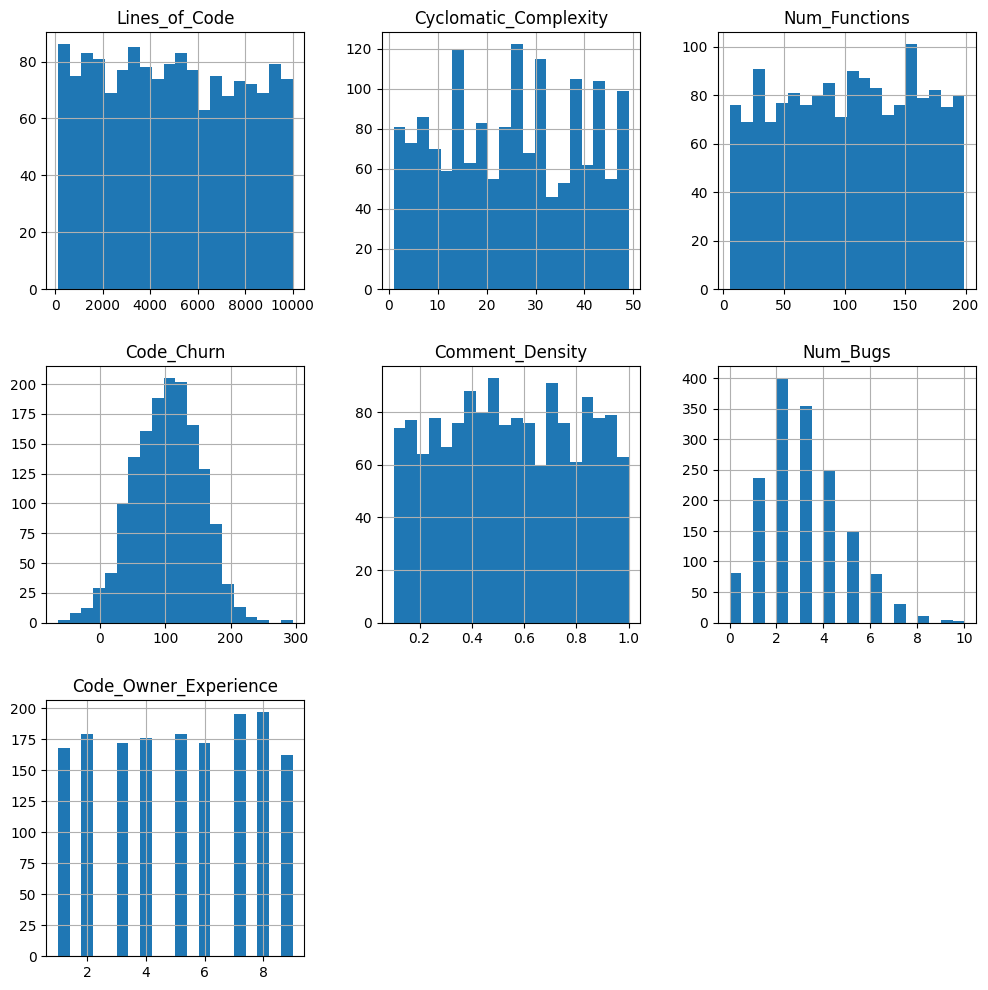

In [ ]:
numerical_data.hist(figsize=(12,12),bins=20)
plt.show()

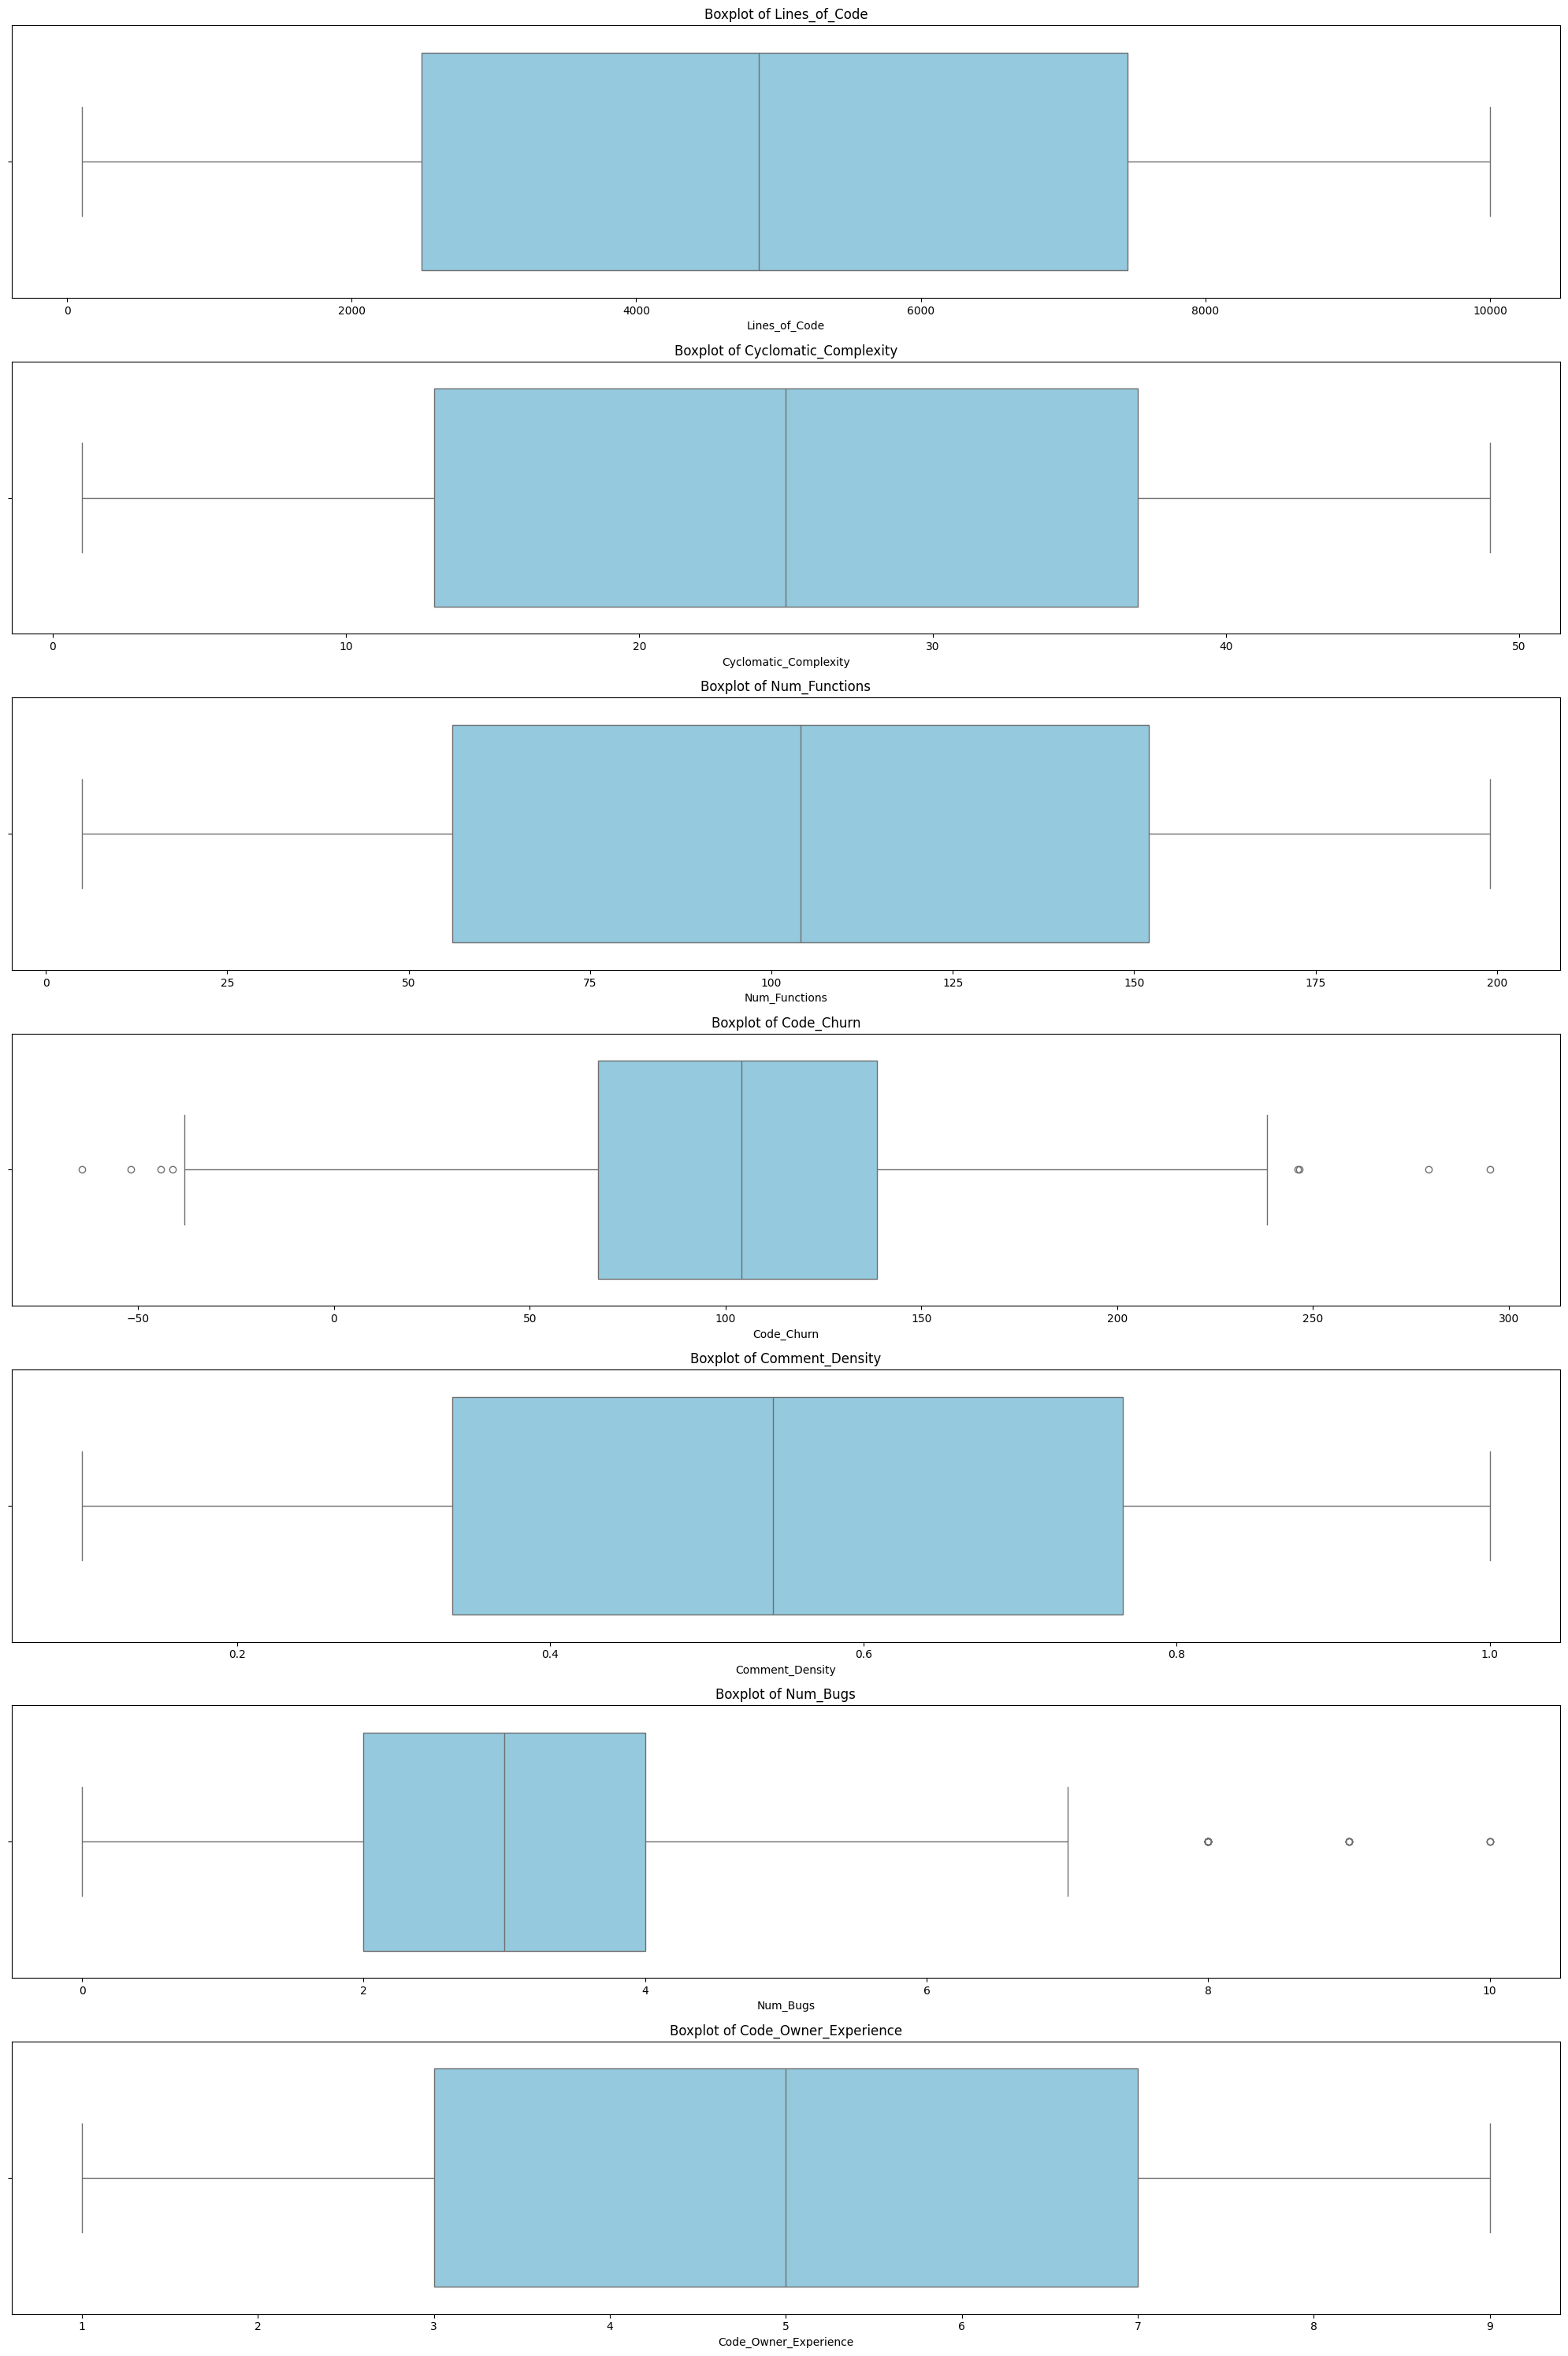

In [ ]:
# Select only numerical columns for boxplot analysis
numeric_cols = eda_df.select_dtypes(include=['int64', 'float64']).columns

# Set up the figure
plt.figure(figsize=(20, 30))


for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 1, i)
    sns.boxplot(x=eda_df[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)
    plt.tight_layout()

plt.show()


**Number of unique values in Numerical Features**

In [ ]:
numerical_data.nunique()


,0
Lines_of_Code,1413
Cyclomatic_Complexity,49
Num_Functions,195
Code_Churn,1520
Comment_Density,1520
Num_Bugs,11
Code_Owner_Experience,9


**Missing values**

In [ ]:
numerical_data.isnull().sum()

,0
Lines_of_Code,80
Cyclomatic_Complexity,0
Num_Functions,0
Code_Churn,80
Comment_Density,80
Num_Bugs,0
Code_Owner_Experience,0


**Number of unique values in Categorical Features**


In [ ]:
unique_counts=categorical_data.nunique()
print(unique_counts)

Has_Unit_Tests    2
Quality_Label     3
dtype: int64


**Barplot of unique value counts in every categorical features**

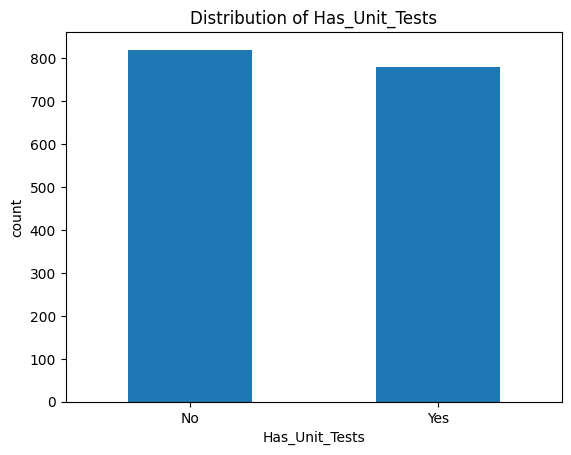

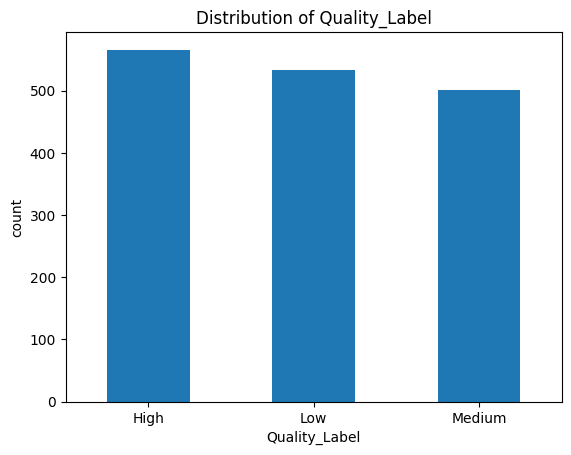

In [ ]:
for col in categorical_features:
    plt.title(f'Distribution of {col}')
    categorical_data[col].value_counts().sort_index().plot(kind='bar', rot=0, xlabel=col,ylabel='count')
    plt.show()

**Correlation Analysis**

In [ ]:
# Calculate the correlation matrix
correlation_matrix = numerical_data.corr()
correlation_matrix


,Lines_of_Code,Cyclomatic_Complexity,Num_Functions,Code_Churn,Comment_Density,Num_Bugs,Code_Owner_Experience
Lines_of_Code,1.000000,0.046746,-0.026398,0.003710,0.019014,-0.029780,0.015243
Cyclomatic_Complexity,0.046746,1.000000,-0.005937,-0.022347,0.041138,-0.076648,-0.019038
Num_Functions,-0.026398,-0.005937,1.000000,-0.005121,-0.002924,0.007963,0.011028
Code_Churn,0.003710,-0.022347,-0.005121,1.000000,0.010962,-0.015592,0.022090
Comment_Density,0.019014,0.041138,-0.002924,0.010962,1.000000,-0.045190,0.028216
Num_Bugs,-0.029780,-0.076648,0.007963,-0.015592,-0.045190,1.000000,-0.008013
Code_Owner_Experience,0.015243,-0.019038,0.011028,0.022090,0.028216,-0.008013,1.000000


**Correlation Heatmap of numerical Features**

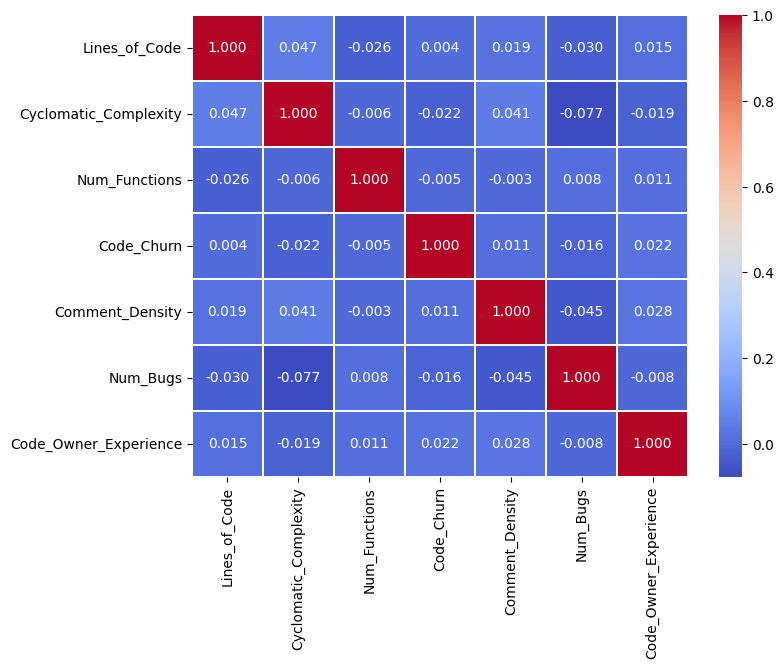

In [ ]:
# Plotting the heatmap for correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.3)
plt.show()

In [ ]:
eda_df["Quality_Label"].value_counts()

,count
Quality_Label,
High,566
Low,533
Medium,501


**Density Plot of Numerical Features.**

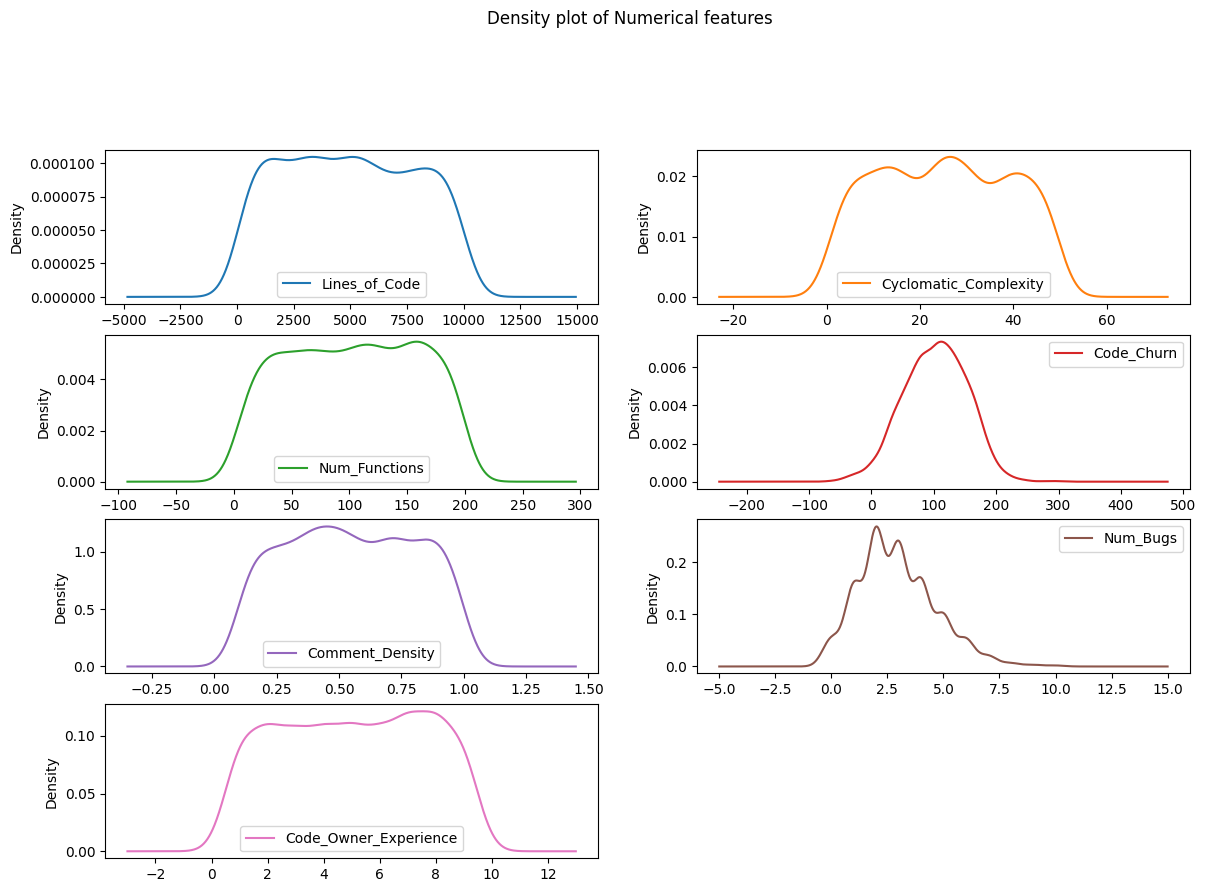

In [ ]:
numerical_data.plot(kind='density',figsize=(14,14),subplots=True,layout=(6,2),title="Density plot of Numerical features",sharex=False)
plt.show()

# Data Proceesing

**Missing values**

In [ ]:
df.isna().sum()

,0
Lines_of_Code,80
Cyclomatic_Complexity,0
Num_Functions,0
Code_Churn,80
Comment_Density,80
Num_Bugs,0
Has_Unit_Tests,0
Code_Owner_Experience,0
Quality_Label,0


In [ ]:
null_cols = df.columns[df.isna().any()].tolist()
print(null_cols)

['Lines_of_Code', 'Code_Churn', 'Comment_Density']


In [ ]:
for col in null_cols:
    if df[col].dtype == df["Has_Unit_Tests"].dtype:
        mode = df[col].mode()[0]
        df[col] = df[col].fillna(mode)
    else:
        df[col] = df[col].fillna(df[col].mean())

In [ ]:
df.isna().sum()

,0
Lines_of_Code,0
Cyclomatic_Complexity,0
Num_Functions,0
Code_Churn,0
Comment_Density,0
Num_Bugs,0
Has_Unit_Tests,0
Code_Owner_Experience,0
Quality_Label,0


**Categorical Values**

In [ ]:
categorical_data=df.select_dtypes(include= 'object')
categorical_data.describe().T

,count,unique,top,freq
Has_Unit_Tests,1600,2,No,820
Quality_Label,1600,3,High,566


In [ ]:
from sklearn.preprocessing import OneHotEncoder

# Find categorical columns
non_numeric_cols = df.select_dtypes(exclude=["number"]).columns.tolist()
df_all_categories = pd.get_dummies(df, columns=non_numeric_cols, drop_first=False)
# Create encoder
ohe = OneHotEncoder(sparse_output=False, drop='first')

# Encode all categorical columns at once
encoded_array = ohe.fit_transform(df[non_numeric_cols])

# Get column names for encoded features
encoded_columns = ohe.get_feature_names_out(non_numeric_cols)

# Convert to DataFrame
encoded_df = pd.DataFrame(encoded_array, columns=encoded_columns, index=df.index)

# Drop original categorical columns and add encoded ones
df = df.drop(columns=non_numeric_cols)
df = pd.concat([df, encoded_df], axis=1)

print(df.head(2))

   Lines_of_Code  Cyclomatic_Complexity  Num_Functions  Code_Churn  \
0          356.0                     31            144   69.567047   
1          227.0                     15            104  131.844422   

   Comment_Density  Num_Bugs  Code_Owner_Experience  Has_Unit_Tests_Yes  \
0         0.467561         2                      4                 1.0   
1         0.795643         2                      5                 0.0   

   Quality_Label_Low  Quality_Label_Medium  
0                0.0                   1.0  
1                0.0                   0.0  


In [ ]:
df.dtypes

,0
Lines_of_Code,float64
Cyclomatic_Complexity,int64
Num_Functions,int64
Code_Churn,float64
Comment_Density,float64
Num_Bugs,int64
Code_Owner_Experience,int64
Has_Unit_Tests_Yes,float64
Quality_Label_Low,float64
Quality_Label_Medium,float64


**Feature Scaling**

In [ ]:
import numpy as np
for col in df.columns.to_list():
    col_var = np.var(df[col])
    print(f"{col}: {round(col_var,2)}")

Lines_of_Code: 7804918.75
Cyclomatic_Complexity: 192.52
Num_Functions: 3078.74
Code_Churn: 2425.59
Comment_Density: 0.06
Num_Bugs: 2.94
Code_Owner_Experience: 6.55
Has_Unit_Tests_Yes: 0.25
Quality_Label_Low: 0.22
Quality_Label_Medium: 0.22


In [ ]:
y=[0,1]
std = np.std(y)
mean= np.mean(y)
print((0-mean)/std)
print((1-mean)/std)
print(std)
print(mean)

-1.0
1.0
0.5
0.5


In [ ]:
features = df.drop(columns=["Has_Unit_Tests_Yes", "Quality_Label_Low","Quality_Label_Medium"]).columns.to_list()
print(features)

['Lines_of_Code', 'Cyclomatic_Complexity', 'Num_Functions', 'Code_Churn', 'Comment_Density', 'Num_Bugs', 'Code_Owner_Experience']


**Features Standardization**

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df[features] = scaler.fit_transform(df[features])
df.head(2)

,Lines_of_Code,Cyclomatic_Complexity,Num_Functions,Code_Churn,Comment_Density,Num_Bugs,Code_Owner_Experience,Has_Unit_Tests_Yes,Quality_Label_Low,Quality_Label_Medium
0,-1.640557,0.426883,0.735710,-0.670154,-0.327804,-0.544701,-0.408378,1.0,0.0,1.0
1,-1.686731,-0.726246,0.014812,0.594355,0.986792,-0.544701,-0.017586,0.0,0.0,0.0


In [ ]:
for col in df.columns.to_list():
    col_var = np.var(df[col])
    print(f"{col}: {round(col_var,2)}")

Lines_of_Code: 1.0
Cyclomatic_Complexity: 1.0
Num_Functions: 1.0
Code_Churn: 1.0
Comment_Density: 1.0
Num_Bugs: 1.0
Code_Owner_Experience: 1.0
Has_Unit_Tests_Yes: 0.25
Quality_Label_Low: 0.22
Quality_Label_Medium: 0.22


**Data Set Splitting**

In [ ]:
from sklearn.model_selection import train_test_split

# Reconstruct the single target variable for stratification and model training
# Based on previous analysis: 0: High, 1: Low, 2: Medium
y_combined = pd.Series(0, index=df.index, dtype=int) # Initialize with 'Average' (0)
y_combined[df['Quality_Label_Low'] == 1] = 1 # 'Fast'
y_combined[df['Quality_Label_Medium'] == 1] = 2 # 'Slow'

X = df.drop(columns=["Quality_Label_Low", "Quality_Label_Medium"])
y = y_combined # This 'y' will be used for both stratification and Y_train/Y_test for models

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)

In [ ]:
print(df["Quality_Label_Low"].value_counts())
print(df["Quality_Label_Medium"].value_counts())


Quality_Label_Low
0.0    1067
1.0     533
Name: count, dtype: int64
Quality_Label_Medium
0.0    1099
1.0     501
Name: count, dtype: int64


In [ ]:
df_with_0 = df[(df["Quality_Label_Low"]==0) & (df["Quality_Label_Medium"]==0)]
df_with_1 = df[df["Quality_Label_Low"]==1]
df_with_2 = df[df["Quality_Label_Medium"]==1]

In [ ]:
reduce_samp_0 = df_with_0.sample(n=501, replace=False)
reduce_samp_1 = df_with_1.sample(n=501, replace=False)


df = pd.concat([reduce_samp_0,df_with_2,reduce_samp_1])


df = df.sample(frac=1)
u_df=df.copy()
df

,Lines_of_Code,Cyclomatic_Complexity,Num_Functions,Code_Churn,Comment_Density,Num_Bugs,Code_Owner_Experience,Has_Unit_Tests_Yes,Quality_Label_Low,Quality_Label_Medium
1093,0.000261,1.075519,-1.625230,0.986067,1.021396,0.621214,0.373207,1.0,1.0,0.0
823,0.557581,0.859307,0.158992,0.945815,-1.678015,-0.544701,-1.189964,1.0,0.0,0.0
635,1.349713,0.498954,1.582765,-0.471568,-1.438186,0.038257,-1.580757,0.0,0.0,1.0
434,-1.422926,1.724154,-0.165412,1.712340,0.000000,-0.544701,1.154793,0.0,0.0,1.0
1585,0.392927,-0.510035,0.483396,0.269720,1.026034,1.204171,1.154793,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
699,1.766002,-0.798317,0.483396,-1.099312,-0.467926,1.204171,0.764000,0.0,0.0,0.0
1468,1.625688,0.138601,-1.643253,0.758379,-0.796264,-1.127658,1.154793,1.0,0.0,0.0
117,-0.994467,-0.077611,-0.778175,-0.625312,-1.556078,-0.544701,-0.799171,0.0,0.0,0.0
82,-0.208420,0.643095,0.843845,-0.210310,0.758756,-0.544701,1.545585,1.0,0.0,0.0


In [ ]:
df.head(10)

,Lines_of_Code,Cyclomatic_Complexity,Num_Functions,Code_Churn,Comment_Density,Num_Bugs,Code_Owner_Experience,Has_Unit_Tests_Yes,Quality_Label_Low,Quality_Label_Medium
1093,0.000261,1.075519,-1.625230,0.986067,1.021396,0.621214,0.373207,1.0,1.0,0.0
823,0.557581,0.859307,0.158992,0.945815,-1.678015,-0.544701,-1.189964,1.0,0.0,0.0
635,1.349713,0.498954,1.582765,-0.471568,-1.438186,0.038257,-1.580757,0.0,0.0,1.0
434,-1.422926,1.724154,-0.165412,1.712340,0.000000,-0.544701,1.154793,0.0,0.0,1.0
1585,0.392927,-0.510035,0.483396,0.269720,1.026034,1.204171,1.154793,1.0,0.0,1.0
495,1.543718,-1.302811,-1.661275,-0.735505,0.000000,1.204171,-0.799171,1.0,0.0,0.0
952,-1.008069,0.931377,1.456608,-0.914102,1.314168,0.038257,1.154793,1.0,0.0,1.0
1488,0.358922,1.147589,-1.553141,0.878339,-1.315635,1.787128,-0.017586,1.0,0.0,1.0
762,1.225506,-1.591094,1.078137,1.098227,0.037456,2.370086,1.545585,0.0,0.0,1.0
702,-0.321531,-0.221752,-1.715343,-0.983580,-1.176822,-0.544701,-1.580757,0.0,0.0,0.0


# **Supervised Learning**

In [ ]:
from sklearn.linear_model import LogisticRegression #logistic regression predicts a probablity.basically picks a side based on the input features. 1 or 0

lr = LogisticRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

from sklearn.metrics import accuracy_score

# Training accuracy
y_train_pred = lr.predict(X_train)
train_acc = accuracy_score(y_train, y_train_pred)

# Testing accuracy
y_test_pred = lr.predict(X_test)
test_acc = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", train_acc)
print("Testing Accuracy:", test_acc)

Training Accuracy: 0.36607142857142855
Testing Accuracy: 0.3458333333333333


In [ ]:
from sklearn.naive_bayes import GaussianNB #almost same as logistic but here inputs are independent

nb = GaussianNB()
nb.fit(X_train, y_train)

y_pred_nb = nb.predict(X_test)

from sklearn.metrics import accuracy_score

# Training accuracy
y_train_pred = nb.predict(X_train)
train_acc = accuracy_score(y_train, y_train_pred)

# Testing accuracy
y_test_pred = nb.predict(X_test)
test_acc = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", train_acc)
print("Testing Accuracy:", test_acc)

Training Accuracy: 0.3821428571428571
Testing Accuracy: 0.3541666666666667


In [ ]:
from sklearn.neural_network import MLPClassifier #

nn = MLPClassifier(
    hidden_layer_sizes=(50, 50),
    max_iter=500,
    random_state=42
)

nn.fit(X_train, y_train)

y_pred_nn = nn.predict(X_test)

from sklearn.metrics import accuracy_score

# Training accuracy
y_train_pred = nn.predict(X_train)
train_acc = accuracy_score(y_train, y_train_pred)

# Testing accuracy
y_test_pred = nn.predict(X_test)
test_acc = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", train_acc)
print("Testing Accuracy:", test_acc)


Training Accuracy: 0.9026785714285714
Testing Accuracy: 0.34375


# Unsupervised Learning

In [ ]:
u_df

,Lines_of_Code,Cyclomatic_Complexity,Num_Functions,Code_Churn,Comment_Density,Num_Bugs,Code_Owner_Experience,Has_Unit_Tests_Yes,Quality_Label_Low,Quality_Label_Medium
1093,0.000261,1.075519,-1.625230,0.986067,1.021396,0.621214,0.373207,1.0,1.0,0.0
823,0.557581,0.859307,0.158992,0.945815,-1.678015,-0.544701,-1.189964,1.0,0.0,0.0
635,1.349713,0.498954,1.582765,-0.471568,-1.438186,0.038257,-1.580757,0.0,0.0,1.0
434,-1.422926,1.724154,-0.165412,1.712340,0.000000,-0.544701,1.154793,0.0,0.0,1.0
1585,0.392927,-0.510035,0.483396,0.269720,1.026034,1.204171,1.154793,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
699,1.766002,-0.798317,0.483396,-1.099312,-0.467926,1.204171,0.764000,0.0,0.0,0.0
1468,1.625688,0.138601,-1.643253,0.758379,-0.796264,-1.127658,1.154793,1.0,0.0,0.0
117,-0.994467,-0.077611,-0.778175,-0.625312,-1.556078,-0.544701,-0.799171,0.0,0.0,0.0
82,-0.208420,0.643095,0.843845,-0.210310,0.758756,-0.544701,1.545585,1.0,0.0,0.0


In [ ]:
u_df

,Lines_of_Code,Cyclomatic_Complexity,Num_Functions,Code_Churn,Comment_Density,Num_Bugs,Code_Owner_Experience,Has_Unit_Tests_Yes,Quality_Label_Low,Quality_Label_Medium
1093,0.000261,1.075519,-1.625230,0.986067,1.021396,0.621214,0.373207,1.0,1.0,0.0
823,0.557581,0.859307,0.158992,0.945815,-1.678015,-0.544701,-1.189964,1.0,0.0,0.0
635,1.349713,0.498954,1.582765,-0.471568,-1.438186,0.038257,-1.580757,0.0,0.0,1.0
434,-1.422926,1.724154,-0.165412,1.712340,0.000000,-0.544701,1.154793,0.0,0.0,1.0
1585,0.392927,-0.510035,0.483396,0.269720,1.026034,1.204171,1.154793,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
699,1.766002,-0.798317,0.483396,-1.099312,-0.467926,1.204171,0.764000,0.0,0.0,0.0
1468,1.625688,0.138601,-1.643253,0.758379,-0.796264,-1.127658,1.154793,1.0,0.0,0.0
117,-0.994467,-0.077611,-0.778175,-0.625312,-1.556078,-0.544701,-0.799171,0.0,0.0,0.0
82,-0.208420,0.643095,0.843845,-0.210310,0.758756,-0.544701,1.545585,1.0,0.0,0.0


In [ ]:
u_df = u_df.drop(["Quality_Label_Low","Quality_Label_Medium"],axis=1)

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(u_df)


In [ ]:
u_df_clusters = u_df.copy()
u_df_clusters['Cluster'] = clusters
u_df_clusters[['Cluster']].head()

,Cluster
1093,2
823,1
635,1
434,2
1585,0


In [ ]:
u_df_clusters.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1503 entries, 1093 to 1237
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Lines_of_Code          1503 non-null   float64
 1   Cyclomatic_Complexity  1503 non-null   float64
 2   Num_Functions          1503 non-null   float64
 3   Code_Churn             1503 non-null   float64
 4   Comment_Density        1503 non-null   float64
 5   Num_Bugs               1503 non-null   float64
 6   Code_Owner_Experience  1503 non-null   float64
 7   Has_Unit_Tests_Yes     1503 non-null   float64
 8   Cluster                1503 non-null   int32  
dtypes: float64(8), int32(1)
memory usage: 111.6 KB


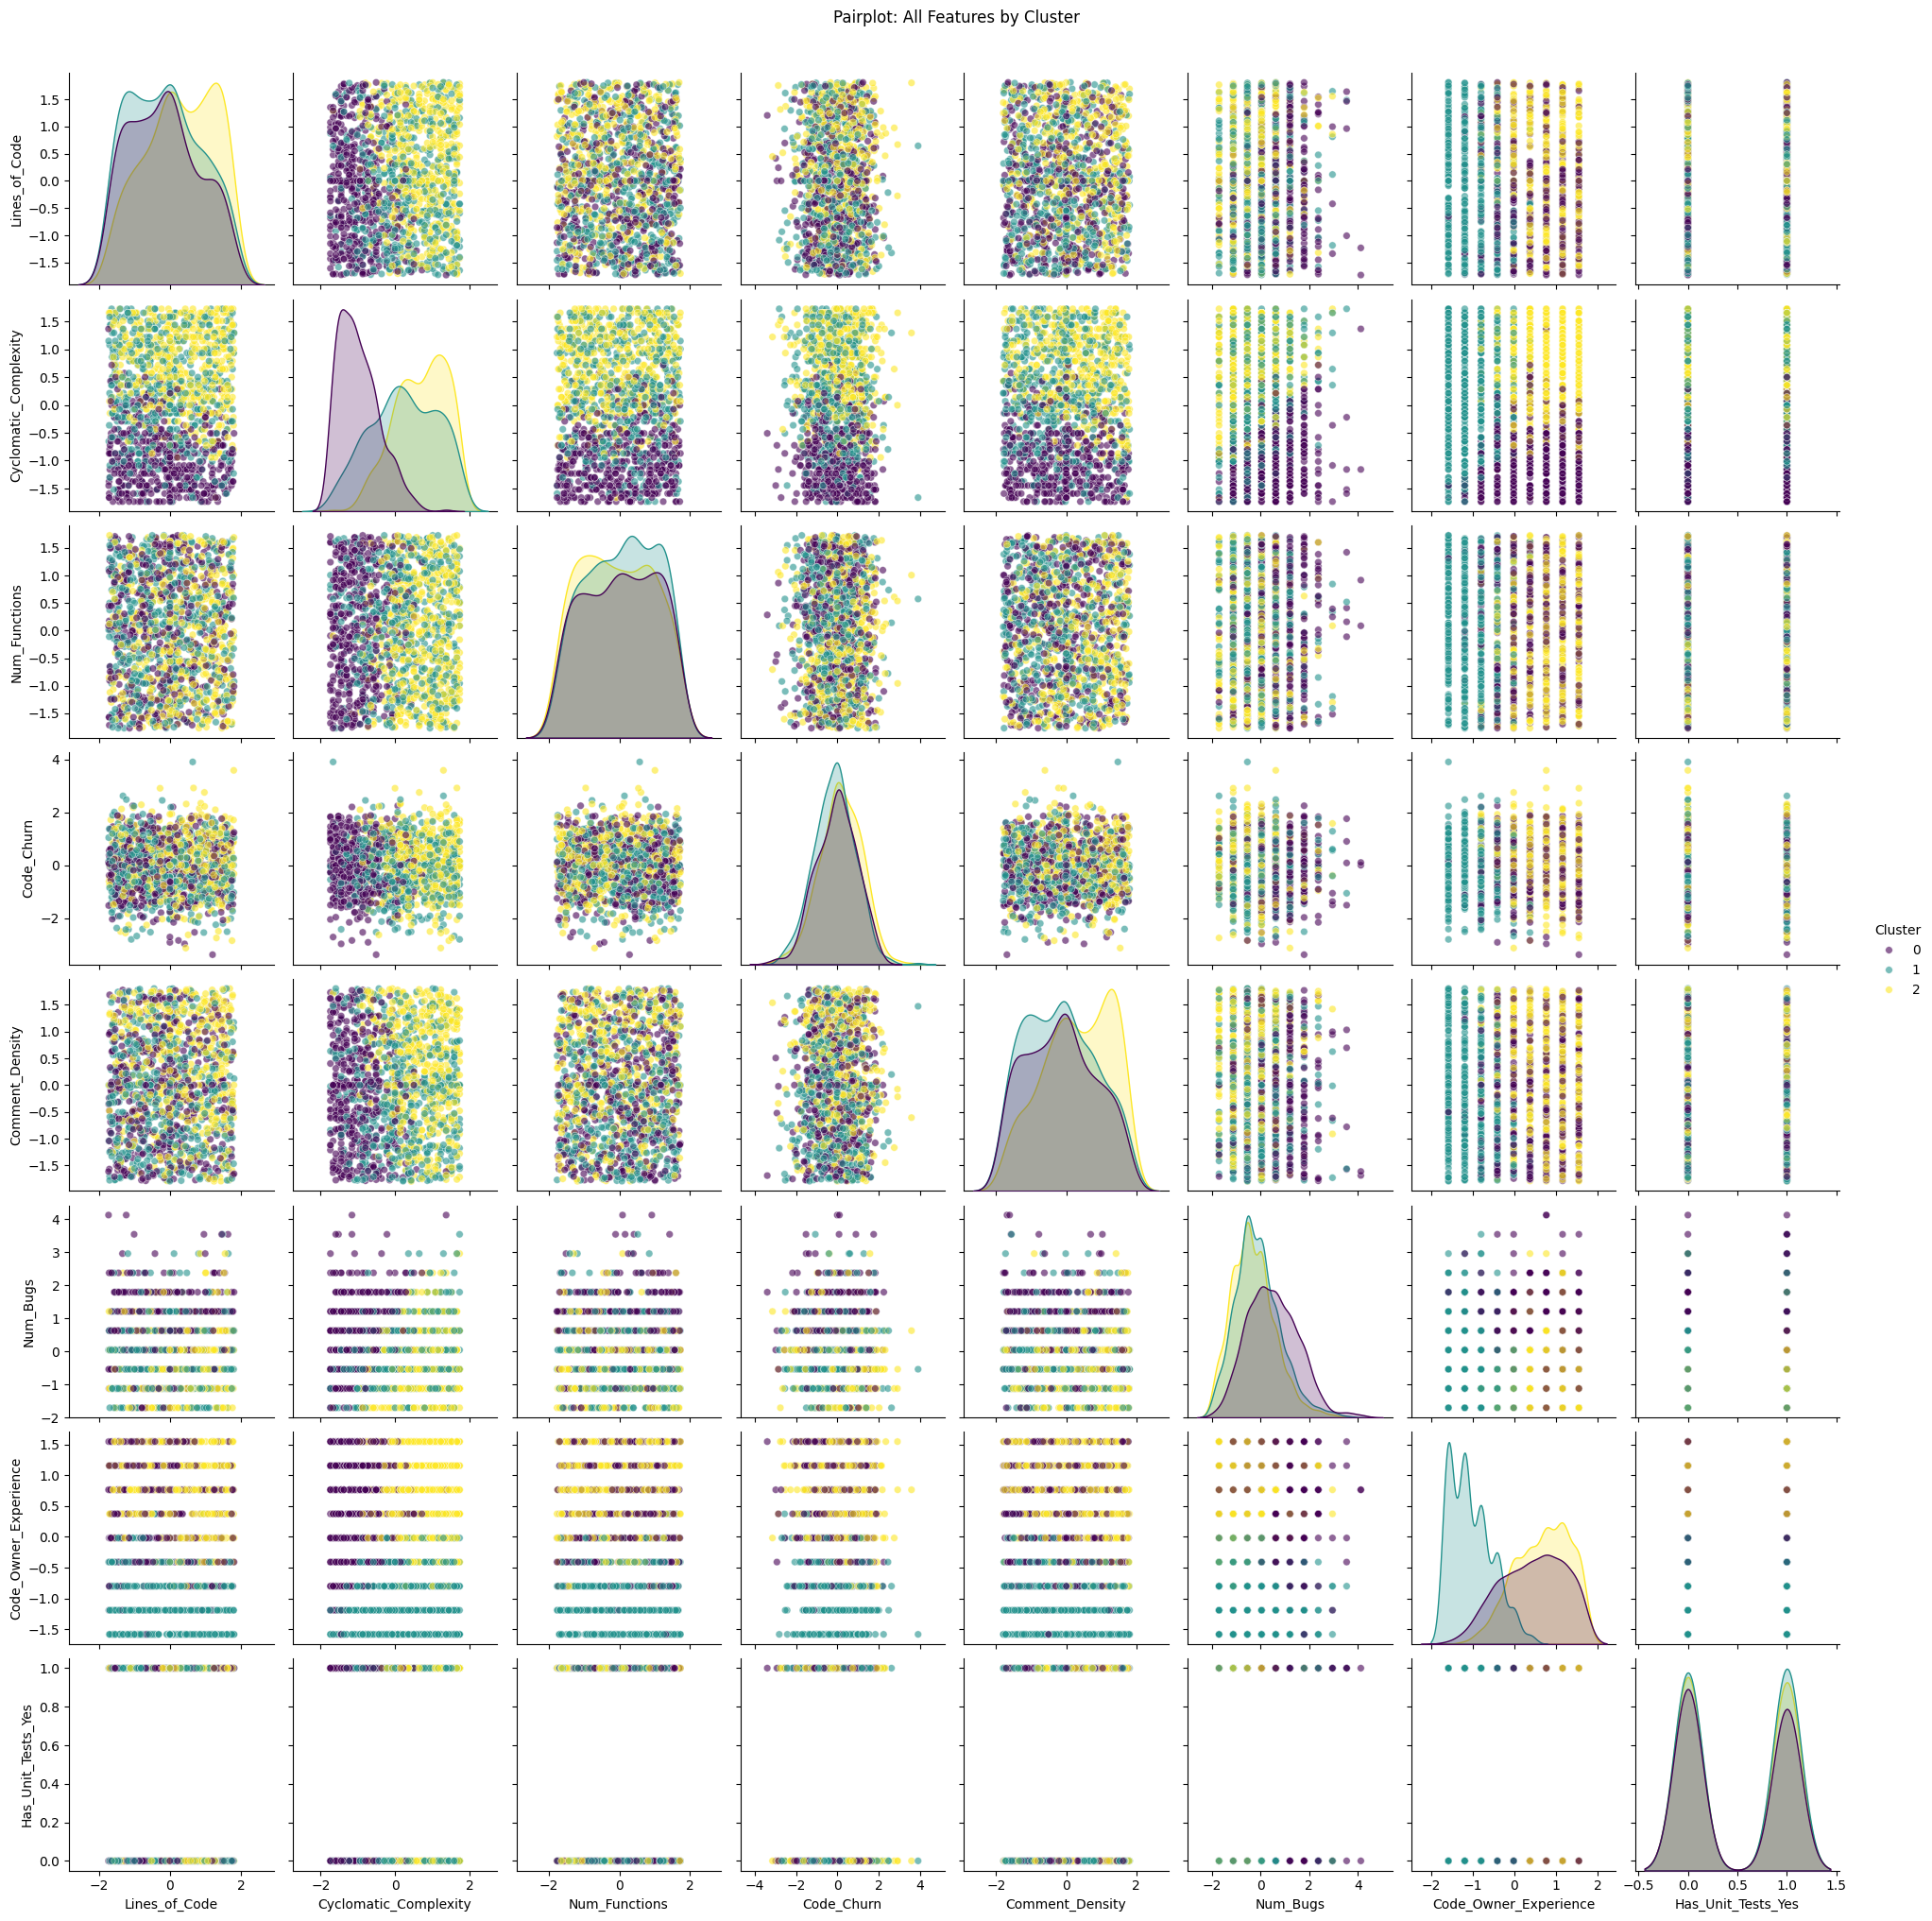

In [ ]:
# Add clusters to your dataframe
u_df_clusters = u_df.copy()
u_df_clusters['Cluster'] = clusters

# Create pairplot for all features
sns.pairplot(u_df_clusters,
             hue='Cluster',
             palette='viridis',
             diag_kind='kde',  # Use kde for diagonal plots
             plot_kws={'alpha': 0.6, 's': 30})  # Customize scatter plots
plt.suptitle('Pairplot: All Features by Cluster', y=1.02)
plt.show()

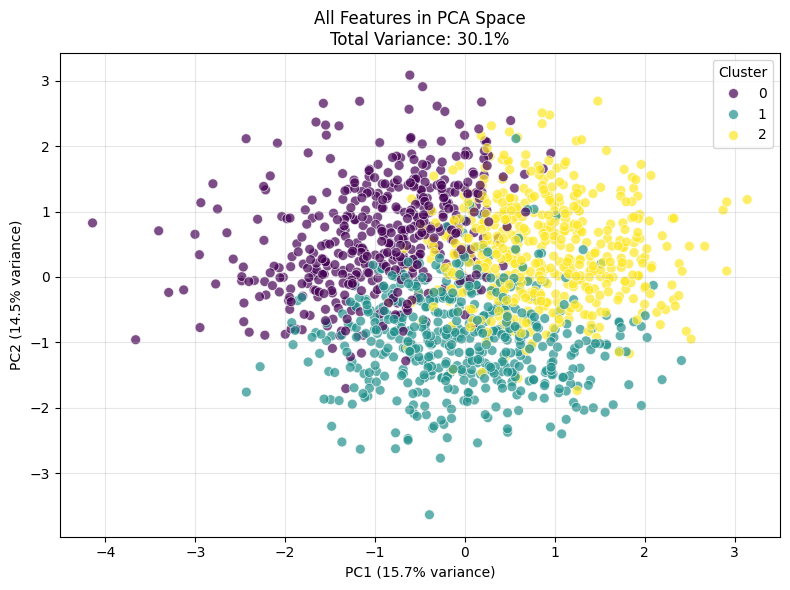

In [ ]:
from sklearn.decomposition import PCA
import pandas as pd

# Apply PCA to reduce all features to 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(u_df)  # Use all features

# Create DataFrame with PCA results
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Cluster'] = clusters

# Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x='PC1', y='PC2',
                hue='Cluster', palette='viridis', alpha=0.7, s=50)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
plt.title(f'All Features in PCA Space\nTotal Variance: {pca.explained_variance_ratio_.sum():.1%}')
plt.legend(title='Cluster')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Model selection/Comparison analysis

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.metrics import r2_score, mean_squared_error


In [ ]:
#Store predictions for classification models
model_preds = {
    "Logistic Regression": y_pred_lr,
    "Naive Bayes": y_pred_nb,
    "Neural Network": y_pred_nn
}


In [ ]:
#Accuracy, Precision, Recall calculation
accuracy = []
precision = []
recall = []

for model, preds in model_preds.items():
    accuracy.append(accuracy_score(y_test, preds))
    precision.append(precision_score(y_test, preds, average='weighted'))
    recall.append(recall_score(y_test, preds, average='weighted'))


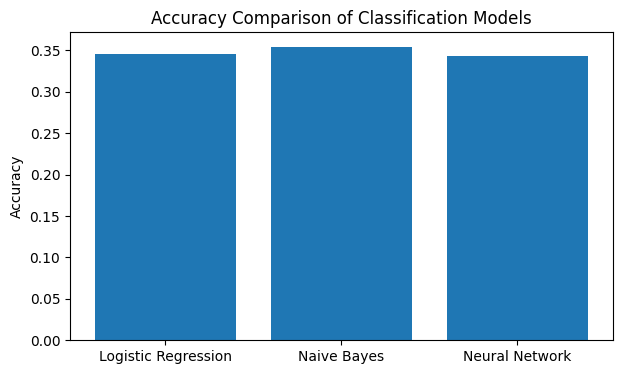

[0.3458333333333333, 0.3541666666666667, 0.34375]


In [ ]:
#Bar chart – Prediction Accuracy
plt.figure(figsize=(7,4))
plt.bar(model_preds.keys(), accuracy)
plt.title("Accuracy Comparison of Classification Models")
plt.ylabel("Accuracy")
plt.show()
print(accuracy)


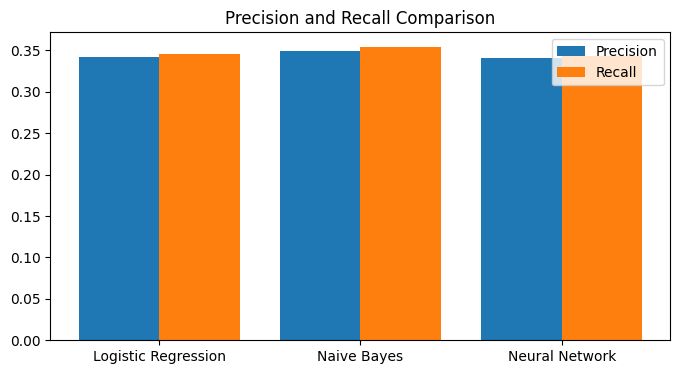

[0.3414761894410038, 0.34869086476466793, 0.3404487568223165]
[0.3458333333333333, 0.3541666666666667, 0.34375]


In [ ]:
#Precision & Recall comparison
x = np.arange(len(model_preds))

plt.figure(figsize=(8,4))
plt.bar(x - 0.2, precision, width=0.4, label='Precision')
plt.bar(x + 0.2, recall, width=0.4, label='Recall')
plt.xticks(x, model_preds.keys())
plt.legend()
plt.title("Precision and Recall Comparison")
plt.show()
print(precision)
print(recall)


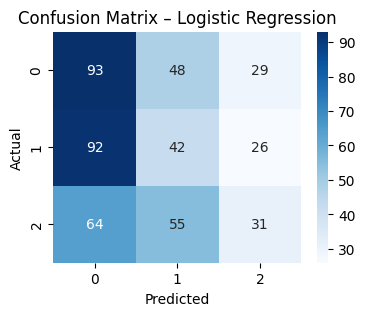

In [ ]:
# Confusion Matrix for Logistic Regression
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(4,3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix – Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()



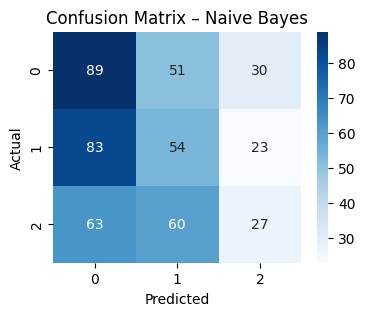

In [ ]:
# Confusion Matrix for Naive Bayes
cm = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(4,3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix – Naive Bayes")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


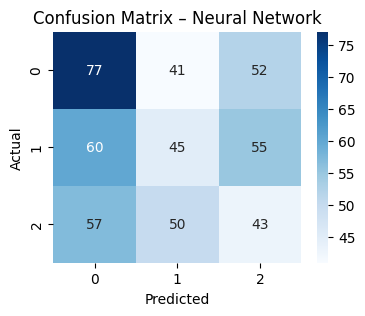

In [ ]:
#Confusion Matrix for neural network
cm = confusion_matrix(y_test, y_pred_nn)

plt.figure(figsize=(4,3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix – Neural Network")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


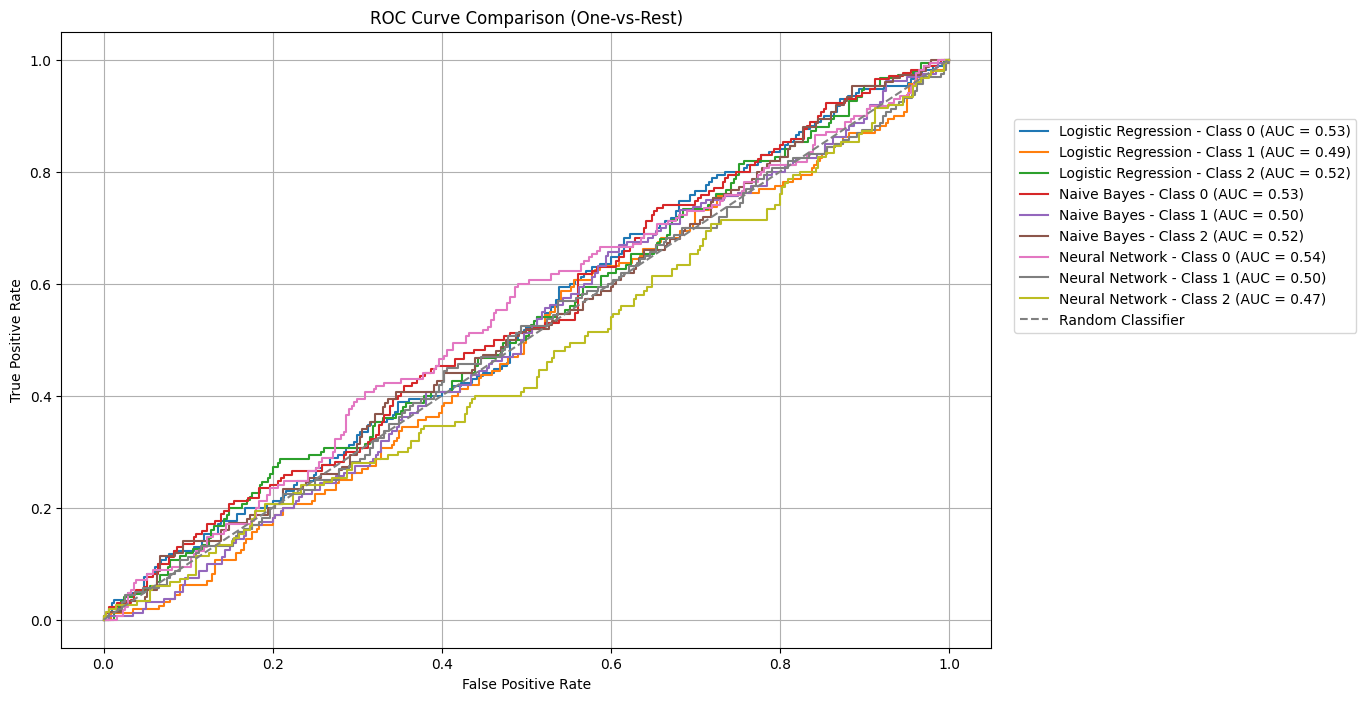

In [ ]:
from sklearn.preprocessing import LabelBinarizer

#ROC Curve and AUC score
plt.figure(figsize=(12, 8))

for model_name, model in zip(
    [ "Logistic Regression", "Naive Bayes", "Neural Network"],
    [ lr, nb, nn]
):
    # Predict probabilities for each class
    y_prob = model.predict_proba(X_test)

    # Binarize y_test for One-vs-Rest approach
    lb = LabelBinarizer()
    y_test_binarized = lb.fit_transform(y_test)

    # Compute ROC curve and AUC for each class (One-vs-Rest)
    for i, class_label in enumerate(lb.classes_):
        fpr, tpr, _ = roc_curve(y_test_binarized[:, i], y_prob[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{model_name} - Class {class_label} (AUC = {roc_auc:.2f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Classifier')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison (One-vs-Rest)")
plt.legend(loc="lower right", bbox_to_anchor=(1.4, 0.5)) # Adjust legend position to avoid overlap
plt.grid(True)
plt.show()
